
# Order Delivery Reliability & Operational Improvement

## Business Problem

Late deliveries can affect customer experience and create operational challenges for an e-commerce retailer. Understanding where delays are concentrated can help a business prioritize further investigation and evaluate potential improvements.

## Research Question

For orders delivered to Rio de Janeiro, Brazil, how does delivery performance vary by seller origin and estimated seller-to-customer distance, and what operational improvements may be worth investigating?

## Objectives

1. Establish a reliable baseline for late-delivery performance.
2. Compare delivery outcomes across seller routes and geographic distance bands.
3. Quantify the uncertainty around the observed difference between key seller-route groups.
4. Build transparent scenarios showing how hypothetical reductions in late deliveries could affect operational outcomes.
5. Translate the findings into practical recommendations while acknowledging the limitations of the data.

## Analytical Approach

Data quality checks → SQL transformations → Delivery performance analysis → Statistical comparison → Improvement scenarios → Business recommendations.

## Dataset

This project uses the Olist Brazilian E-Commerce Public Dataset, which contains linked records of orders, items, payments, customers, sellers, products and reviews.

## Scope and Limitations

This is an observational analysis. Associations between seller location, distance, delivery performance and reviews do not establish causation. Seller-to-customer distances are approximate straight-line estimates based on postal-code-prefix coordinates, not actual transport routes. Improvement scenarios are illustrative estimates, not forecasts or guaranteed financial gains.


In [8]:

# 1. Load the source data

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# The notebook and CSV files are currently in the same folder.
DATA_DIR = Path.cwd()

files = {
    "orders": "olist_orders_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "customers": "olist_customers_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
}

def find_csv(filename):
    """Find either a normal CSV or a zipped CSV."""
    for candidate in [filename, filename + ".zip"]:
        path = DATA_DIR / candidate
        if path.is_file():
            return path

    raise FileNotFoundError(
        f"Could not find {filename} or {filename}.zip "
        f"in {DATA_DIR}"
    )

# Load the six tables required for our core analysis.
tables = {}

for name, filename in files.items():
    path = find_csv(filename)
    tables[name] = pd.read_csv(path)

# Create a concise inventory of the loaded data.
inventory = pd.DataFrame([
    {
        "table": name,
        "rows": len(df),
        "columns": len(df.columns),
    }
    for name, df in tables.items()
])

print("DATA LOADED SUCCESSFULLY")
print("Source folder:", DATA_DIR)

display(inventory)


DATA LOADED SUCCESSFULLY
Source folder: /home/jupyter/Proj3 funnel Analysis


,table,rows,columns
0,orders,99441,8
1,order_items,112650,7
2,payments,103886,5
3,reviews,99224,7
4,customers,99441,5
5,sellers,3095,4



### Data Overview

The analysis uses six related tables from the Olist Brazilian E-Commerce Public Dataset. The orders table provides the main analytical unit, while order items, payments, reviews, customers and sellers provide additional information.

Because these tables operate at different levels of detail, item, payment and review records must be aggregated appropriately before they are joined to orders. This prevents order counts and financial values from being accidentally multiplied.


In [9]:
# 2. Transform the source tables using SQL

import duckdb

con = duckdb.connect(database=":memory:")

# Register our Pandas tables so DuckDB can query them.
for table_name, df in tables.items():
    con.register(table_name, df)

sql_query = """
WITH item_metrics AS (
    SELECT
        order_id,
        COUNT(*) AS item_lines,
        COUNT(DISTINCT seller_id) AS distinct_sellers,
        SUM(price) AS item_value,
        SUM(freight_value) AS freight_value
    FROM order_items
    GROUP BY order_id
),

payment_metrics AS (
    SELECT
        order_id,
        SUM(payment_value) AS paid_amount,
        COUNT(*) AS payment_records,
        COUNT(DISTINCT payment_type) AS distinct_payment_types
    FROM payments
    GROUP BY order_id
),

review_metrics AS (
    SELECT
        order_id,
        COUNT(*) AS review_records,
        AVG(review_score) AS avg_review_score
    FROM reviews
    GROUP BY order_id
)

SELECT
    o.order_id,
    o.customer_id,
    c.customer_unique_id,
    c.customer_state,
    o.order_status,

    CAST(o.order_purchase_timestamp AS TIMESTAMP)
        AS order_purchase_timestamp,
    CAST(o.order_approved_at AS TIMESTAMP)
        AS order_approved_at,
    CAST(o.order_delivered_carrier_date AS TIMESTAMP)
        AS order_delivered_carrier_date,
    CAST(o.order_delivered_customer_date AS TIMESTAMP)
        AS order_delivered_customer_date,
    CAST(o.order_estimated_delivery_date AS TIMESTAMP)
        AS order_estimated_delivery_date,

    i.item_lines,
    i.distinct_sellers,
    i.item_value,
    i.freight_value,

    p.paid_amount,
    p.payment_records,
    p.distinct_payment_types,

    r.review_records,
    r.avg_review_score,

    CASE
        WHEN o.order_status = 'delivered'
         AND o.order_delivered_customer_date IS NOT NULL
         AND o.order_estimated_delivery_date IS NOT NULL
        THEN
            CAST(
                CAST(
                    o.order_delivered_customer_date AS TIMESTAMP
                ) AS DATE
            )
            >
            CAST(
                CAST(
                    o.order_estimated_delivery_date AS TIMESTAMP
                ) AS DATE
            )
        ELSE NULL
    END AS arrived_late_calendar

FROM orders AS o

LEFT JOIN customers AS c
    ON o.customer_id = c.customer_id

LEFT JOIN item_metrics AS i
    ON o.order_id = i.order_id

LEFT JOIN payment_metrics AS p
    ON o.order_id = p.order_id

LEFT JOIN review_metrics AS r
    ON o.order_id = r.order_id
"""

analysis_final = con.execute(sql_query).df()

print("SQL TRANSFORMATION — VALIDATION")

print("Rows:", len(analysis_final))
print("Unique orders:", analysis_final["order_id"].nunique())
print(
    "Repeated order IDs:",
    analysis_final["order_id"].duplicated().sum()
)

eligible = analysis_final["arrived_late_calendar"].notna()
delivery_final = analysis_final.loc[eligible]

late_count = int(
    delivery_final["arrived_late_calendar"].astype(bool).sum()
)

print("Delivered orders with usable dates:", len(delivery_final))
print("Late orders:", late_count)
print(f"Late-delivery rate: {late_count / len(delivery_final):.2%}")

assert len(analysis_final) == 99441
assert analysis_final["order_id"].is_unique
assert len(delivery_final) == 96470
assert late_count == 6534

print("\nAll validation checks passed!")

SQL TRANSFORMATION — VALIDATION
Rows: 99441
Unique orders: 99441
Repeated order IDs: 0
Delivered orders with usable dates: 96470
Late orders: 6534
Late-delivery rate: 6.77%

All validation checks passed!



## 3. Key Finding: Delivery Performance by Seller Route

To investigate delivery delays, we focus on orders delivered to Rio de Janeiro (RJ). We classify each order according to the locations of its sellers and compare late-delivery rates, customer review scores, and carrier-to-customer delivery times.

This comparison helps identify routes that may warrant further operational investigation. It is observational: differences between seller routes do not establish that seller location causes delivery delays.


In [10]:

# 3. Compare delivery performance by seller route

import math

# Create unique order-seller pairs and attach seller locations.
order_sellers = (
    tables["order_items"][["order_id", "seller_id"]]
    .drop_duplicates()
    .merge(
        tables["sellers"][["seller_id", "seller_state"]],
        on="seller_id",
        how="left",
        validate="many_to_one",
    )
)

# Collect the distinct seller states associated with each order.
seller_profiles = (
    order_sellers.groupby("order_id")["seller_state"]
    .agg(lambda s: sorted(set(s.dropna())))
    .reset_index(name="seller_states")
)

def classify_route(states):
    states = set(states)

    if not states:
        return "Unknown seller state"
    elif states == {"RJ"}:
        return "RJ sellers only"
    elif "RJ" in states:
        return "Mix of RJ and other states"
    else:
        return "Outside-RJ sellers only"

seller_profiles["seller_route_type"] = (
    seller_profiles["seller_states"].apply(classify_route)
)

# Keep delivered orders with valid actual and estimated delivery dates.
delivery_final = analysis_final.loc[
    analysis_final["arrived_late_calendar"].notna()
].copy()

# Focus on orders delivered to Rio de Janeiro.
rj_delivery_final = delivery_final.loc[
    delivery_final["customer_state"].eq("RJ")
].merge(
    seller_profiles[["order_id", "seller_route_type"]],
    on="order_id",
    how="left",
    validate="one_to_one",
)

# Calculate carrier-to-customer delivery time.
rj_delivery_final["carrier_to_delivery_days"] = (
    rj_delivery_final["order_delivered_customer_date"]
    - rj_delivery_final["order_delivered_carrier_date"]
).dt.total_seconds() / 86400

# Exclude negative intervals from duration summaries,
# without deleting the underlying orders.
rj_delivery_final.loc[
    rj_delivery_final["carrier_to_delivery_days"] < 0,
    "carrier_to_delivery_days",
] = float("nan")

# Summarize each seller-route group.
route_summary_final = (
    rj_delivery_final.groupby("seller_route_type", dropna=False)
    .agg(
        delivered_orders=("order_id", "nunique"),
        late_orders=("arrived_late_calendar", "sum"),
        late_rate=("arrived_late_calendar", "mean"),
        average_review_score=("avg_review_score", "mean"),
        median_carrier_to_delivery_days=(
            "carrier_to_delivery_days", "median"
        ),
    )
    .reset_index()
)

route_summary_final["late_rate_percent"] = (
    route_summary_final["late_rate"] * 100
).round(2)

print("DELIVERY PERFORMANCE BY SELLER ROUTE")

display(
    route_summary_final[
        [
            "seller_route_type",
            "delivered_orders",
            "late_orders",
            "late_rate_percent",
            "average_review_score",
            "median_carrier_to_delivery_days",
        ]
    ].round(2)
)

# Compare outside-RJ sellers with RJ-seller-only orders.
outside = rj_delivery_final.loc[
    rj_delivery_final["seller_route_type"]
    == "Outside-RJ sellers only"
]

local = rj_delivery_final.loc[
    rj_delivery_final["seller_route_type"] == "RJ sellers only"
]

n1, x1 = len(outside), int(outside["arrived_late_calendar"].sum())
n2, x2 = len(local), int(local["arrived_late_calendar"].sum())

p1, p2 = x1 / n1, x2 / n2
difference = p1 - p2

# Approximate 95% confidence interval for the difference.
se_ci = math.sqrt(
    p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2
)

lower = difference - 1.96 * se_ci
upper = difference + 1.96 * se_ci

# Two-sided, pooled two-proportion z-test.
pooled = (x1 + x2) / (n1 + n2)

se_null = math.sqrt(
    pooled * (1 - pooled) * (1 / n1 + 1 / n2)
)

z_stat = difference / se_null
p_value = math.erfc(abs(z_stat) / math.sqrt(2))

print("\nSTATISTICAL COMPARISON")
print(f"Outside-RJ seller late rate: {p1:.2%}")
print(f"RJ-seller-only late rate: {p2:.2%}")
print(f"Difference: {difference:.2%}")
print(f"95% confidence interval: {lower:.2%} to {upper:.2%}")
print(f"Two-sided p-value: {p_value:.4g}")

# Basic validation checks.
assert rj_delivery_final["order_id"].is_unique
assert n1 == 11389
assert n2 == 944

print("\nOrder uniqueness and route-count checks passed.")


DELIVERY PERFORMANCE BY SELLER ROUTE


,seller_route_type,delivered_orders,late_orders,late_rate_percent,average_review_score,median_carrier_to_delivery_days
0,Mix of RJ and other states,17,0,0.0,2.00,4.07
1,Outside-RJ sellers only,11389,1450,12.73,3.93,9.09
2,RJ sellers only,944,45,4.77,4.40,2.23



STATISTICAL COMPARISON
Outside-RJ seller late rate: 12.73%
RJ-seller-only late rate: 4.77%
Difference: 7.96%
95% confidence interval: 6.47% to 9.46%
Two-sided p-value: 5.805e-13

Order uniqueness and route-count checks passed.


In [15]:
# Robustness check: compare one eligible order per customer

customer_check = rj_delivery_final.loc[
    rj_delivery_final["seller_route_type"].isin([
        "Outside-RJ sellers only",
        "RJ sellers only",
    ])
].copy()

customer_check["order_purchase_timestamp"] = pd.to_datetime(
    customer_check["order_purchase_timestamp"],
    errors="coerce",
)

customer_check = (
    customer_check
    .sort_values("order_purchase_timestamp")
    .drop_duplicates("customer_unique_id", keep="first")
)

customer_check_summary = (
    customer_check
    .groupby("seller_route_type")
    .agg(
        customers=("customer_unique_id", "nunique"),
        late_orders=("arrived_late_calendar", "sum"),
        late_delivery_rate=("arrived_late_calendar", "mean"),
    )
    .reset_index()
)

customer_check_summary["late_delivery_rate"] *= 100

display(customer_check_summary.round(2))

,seller_route_type,customers,late_orders,late_delivery_rate
0,Outside-RJ sellers only,10985,1396,12.71
1,RJ sellers only,916,45,4.91



### Key Finding

Orders delivered to Rio de Janeiro involving only outside-state sellers had a late-delivery rate of 12.73%, compared with 4.77% for orders involving only RJ sellers. The observed difference was 7.96 percentage points (95% confidence interval: 6.47–9.46 percentage points).

The median interval from carrier handoff to customer delivery was also longer for outside-RJ seller orders: 9.09 days versus 2.23 days.

These results identify a route-related pattern worth investigating. They do not establish causation, and differences in carriers, product mix, seller characteristics, and shipping distance may contribute to the observed gap.

The 17 orders involving a mix of RJ and other-state sellers are excluded from this two-group comparison because they form a very small, distinct group.


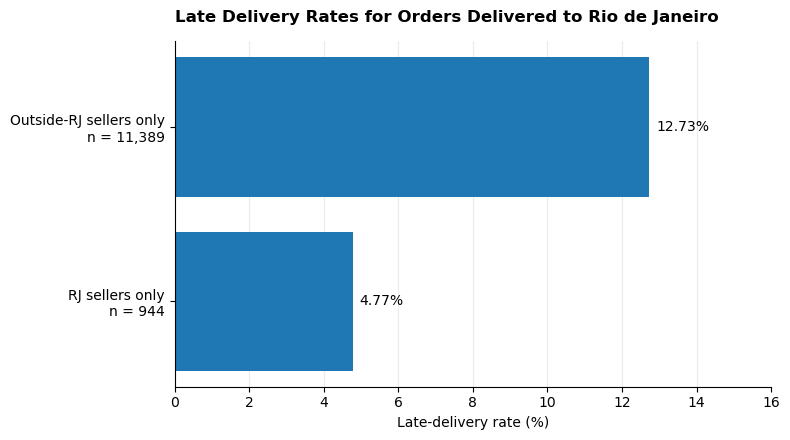

In [11]:

# 4. Visualize the main delivery-performance finding

plot_data = route_summary_final.loc[
    route_summary_final["seller_route_type"].isin([
        "Outside-RJ sellers only",
        "RJ sellers only",
    ])
].copy()

plot_data["group_label"] = plot_data.apply(
    lambda row: (
        f"{row['seller_route_type']}\n"
        f"n = {int(row['delivered_orders']):,}"
    ),
    axis=1,
)

plot_data = plot_data.sort_values("late_rate_percent")

fig, ax = plt.subplots(figsize=(8, 4.5))

bars = ax.barh(
    plot_data["group_label"],
    plot_data["late_rate_percent"],
)

ax.set_title(
    "Late Delivery Rates for Orders Delivered to Rio de Janeiro",
    loc="left",
    pad=14,
    fontweight="bold",
)
ax.set_xlabel("Late-delivery rate (%)")
ax.set_ylabel("")
ax.bar_label(
    bars,
    labels=[
        f"{rate:.2f}%"
        for rate in plot_data["late_rate_percent"]
    ],
    padding=5,
)
ax.set_xlim(0, 16)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()



## 4. Investigating Estimated Shipping Distance

We next examine whether estimated seller-to-customer distance is associated with late delivery for orders shipped from São Paulo (SP) to customers in Rio de Janeiro (RJ).

Postal-code prefixes are matched to representative coordinates, and straight-line distance is calculated using the Haversine formula. These distances approximate geographic separation; they are not actual road or carrier routes.

We compare delivery outcomes across distance quartiles to identify patterns worth investigating, without assuming that distance alone causes delays.


In [12]:

# 4. Analyze estimated distance and delivery performance

# Identify orders delivered to RJ involving SP sellers only.
origin_by_order = (
    order_sellers.groupby("order_id")["seller_state"]
    .agg(lambda s: sorted(set(s.dropna())))
    .reset_index(name="seller_states")
)

origin_by_order["seller_origin_state"] = (
    origin_by_order["seller_states"]
    .apply(lambda states: states[0] if len(states) == 1
           else "Multiple" if states else "Unknown")
)

sp_rj = rj_delivery_final.merge(
    origin_by_order[["order_id", "seller_origin_state"]],
    on="order_id",
    how="left",
    validate="one_to_one",
)

sp_rj = sp_rj.loc[
    sp_rj["seller_origin_state"].eq("SP")
].copy()

# Standardize postal-code prefixes for matching.
def zip_key(series):
    return (
        pd.to_numeric(series, errors="coerce")
        .astype("Int64")
        .astype("string")
        .str.zfill(5)
    )

customer_zips = (
    tables["orders"][["order_id", "customer_id"]]
    .merge(
        tables["customers"][
            ["customer_id", "customer_zip_code_prefix"]
        ],
        on="customer_id",
        how="left",
        validate="one_to_one",
    )
)

customer_zips["customer_zip_key"] = zip_key(
    customer_zips["customer_zip_code_prefix"]
)

seller_locations = tables["sellers"][
    ["seller_id", "seller_zip_code_prefix"]
].copy()

seller_locations["seller_zip_key"] = zip_key(
    seller_locations["seller_zip_code_prefix"]
)

target_pairs = (
    order_sellers.loc[
        order_sellers["order_id"].isin(sp_rj["order_id"])
        & order_sellers["seller_state"].eq("SP"),
        ["order_id", "seller_id"],
    ]
    .merge(
        seller_locations,
        on="seller_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        customer_zips[["order_id", "customer_zip_key"]],
        on="order_id",
        how="left",
        validate="many_to_one",
    )
)

# Load only the geolocation columns needed.
geo_path = find_csv("olist_geolocation_dataset.csv")

geo = pd.read_csv(
    geo_path,
    usecols=[
        "geolocation_zip_code_prefix",
        "geolocation_lat",
        "geolocation_lng",
    ],
)

geo["zip_key"] = zip_key(geo["geolocation_zip_code_prefix"])

# Multiple coordinates can exist per prefix; use the median.
geo_centroids = (
    geo.groupby("zip_key", dropna=True)
    .agg(
        latitude=("geolocation_lat", "median"),
        longitude=("geolocation_lng", "median"),
    )
    .reset_index()
)

seller_geo = geo_centroids.rename(
    columns={
        "zip_key": "seller_zip_key",
        "latitude": "seller_lat",
        "longitude": "seller_lng",
    }
)

customer_geo = geo_centroids.rename(
    columns={
        "zip_key": "customer_zip_key",
        "latitude": "customer_lat",
        "longitude": "customer_lng",
    }
)

routes = (
    target_pairs
    .merge(
        seller_geo,
        on="seller_zip_key",
        how="left",
        validate="many_to_one",
    )
    .merge(
        customer_geo,
        on="customer_zip_key",
        how="left",
        validate="many_to_one",
    )
)

# Calculate Haversine distance in kilometres.
coordinate_columns = [
    "seller_lat", "seller_lng",
    "customer_lat", "customer_lng",
]

valid = routes[coordinate_columns].notna().all(axis=1)

lat1 = np.radians(routes.loc[valid, "seller_lat"].to_numpy())
lon1 = np.radians(routes.loc[valid, "seller_lng"].to_numpy())
lat2 = np.radians(routes.loc[valid, "customer_lat"].to_numpy())
lon2 = np.radians(routes.loc[valid, "customer_lng"].to_numpy())

a = (
    np.sin((lat2 - lat1) / 2) ** 2
    + np.cos(lat1) * np.cos(lat2)
    * np.sin((lon2 - lon1) / 2) ** 2
)

routes["estimated_distance_km"] = np.nan
routes.loc[valid, "estimated_distance_km"] = (
    6371 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
)

# Reduce to one representative distance per order.
distance_by_order = (
    routes.groupby("order_id")
    .agg(
        estimated_distance_km=("estimated_distance_km", "median")
    )
    .reset_index()
)

distance_analysis = sp_rj.merge(
    distance_by_order,
    on="order_id",
    how="left",
    validate="one_to_one",
)

distance_analysis["carrier_to_delivery_days"] = (
    distance_analysis["order_delivered_customer_date"]
    - distance_analysis["order_delivered_carrier_date"]
).dt.total_seconds() / 86400

distance_analysis.loc[
    distance_analysis["carrier_to_delivery_days"] < 0,
    "carrier_to_delivery_days",
] = np.nan

# Create four distance groups using available estimates.
distance_valid = distance_analysis.dropna(
    subset=["estimated_distance_km"]
).copy()

distance_valid["distance_band"] = pd.qcut(
    distance_valid["estimated_distance_km"],
    q=4,
    duplicates="drop",
)

distance_summary_final = (
    distance_valid.groupby("distance_band", observed=True)
    .agg(
        delivered_orders=("order_id", "nunique"),
        late_orders=("arrived_late_calendar", "sum"),
        late_rate=("arrived_late_calendar", "mean"),
        median_distance_km=("estimated_distance_km", "median"),
        median_transit_days=("carrier_to_delivery_days", "median"),
        average_review_score=("avg_review_score", "mean"),
    )
    .reset_index()
)

distance_summary_final["late_rate_percent"] = (
    distance_summary_final["late_rate"] * 100
).round(2)

print("SP-ORIGIN ORDERS DELIVERED TO RJ")
print("Eligible orders:", len(distance_analysis))
print(
    "Orders with estimated distance:",
    int(distance_analysis["estimated_distance_km"].notna().sum()),
)

print("\nDELIVERY PERFORMANCE BY DISTANCE QUARTILE")
display(
    distance_summary_final[
        [
            "distance_band",
            "delivered_orders",
            "late_orders",
            "late_rate_percent",
            "median_distance_km",
            "median_transit_days",
            "average_review_score",
        ]
    ].round(2)
)


SP-ORIGIN ORDERS DELIVERED TO RJ
Eligible orders: 8128
Orders with estimated distance: 8101

DELIVERY PERFORMANCE BY DISTANCE QUARTILE


,distance_band,delivered_orders,late_orders,late_rate_percent,median_distance_km,median_transit_days,average_review_score
0,"(0.993, 342.979]",2026,257,12.69,322.88,8.12,3.85
1,"(342.979, 383.587]",2025,225,11.11,358.13,8.06,4.00
2,"(383.587, 542.156]",2025,338,16.69,458.95,9.87,3.88
3,"(542.156, 1242.948]",2025,328,16.2,597.62,10.98,3.85


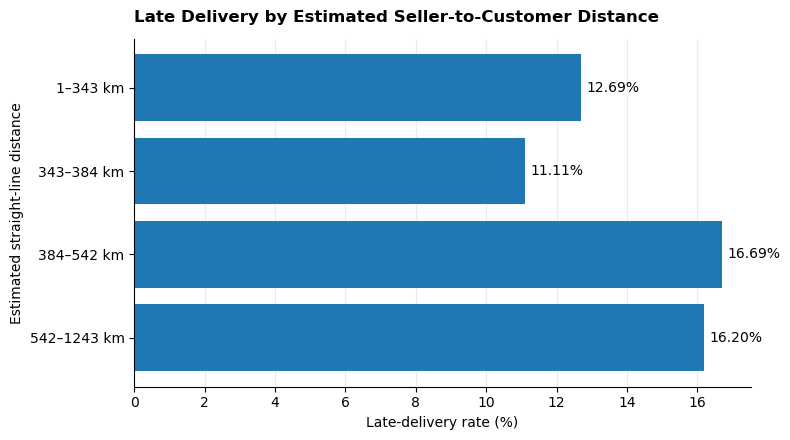

In [13]:

# Visualize late delivery across estimated distance quartiles

distance_plot = distance_summary_final.sort_values(
    "median_distance_km"
).copy()

distance_plot["distance_label"] = [
    f"{band.left:.0f}–{band.right:.0f} km"
    for band in distance_plot["distance_band"]
]

fig, ax = plt.subplots(figsize=(8, 4.5))

bars = ax.barh(
    distance_plot["distance_label"],
    distance_plot["late_rate_percent"],
)

ax.invert_yaxis()
ax.set_title(
    "Late Delivery by Estimated Seller-to-Customer Distance",
    loc="left",
    pad=12,
    fontweight="bold",
)
ax.set_xlabel("Late-delivery rate (%)")
ax.set_ylabel("Estimated straight-line distance")
ax.bar_label(bars, fmt="%.2f%%", padding=4)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()



## 5. Operational Improvement Scenarios

Our analysis found a higher late-delivery rate for orders delivered to Rio de Janeiro involving only outside-RJ sellers than for orders involving only RJ sellers.

To quantify the potential scale of improvement, we model hypothetical relative reductions of 10%, 20%, and 30% in the baseline late-delivery rate. We also compare these scenarios with the observed rate for RJ-seller-only orders.

These scenarios illustrate the possible operational impact of improvement assumptions. They are not forecasts, and matching the local-seller rate is a benchmark rather than a guaranteed or necessarily achievable target.


In [14]:

# 5. Model potential reductions in late deliveries

# Use the route comparison dataset already created above.
outside_rj = rj_delivery_final.loc[
    rj_delivery_final["seller_route_type"]
    == "Outside-RJ sellers only"
].copy()

local_rj = rj_delivery_final.loc[
    rj_delivery_final["seller_route_type"]
    == "RJ sellers only"
].copy()

# Establish the observed baseline.
baseline_orders = outside_rj["order_id"].nunique()
baseline_late = int(
    outside_rj["arrived_late_calendar"].sum()
)
baseline_rate = baseline_late / baseline_orders

# Use the local-seller rate as a comparison benchmark.
local_rate = (
    local_rj["arrived_late_calendar"].mean()
)

print("BASELINE: OUTSIDE-RJ SELLERS SHIPPING TO RJ")
print(f"Delivered orders: {baseline_orders:,}")
print(f"Late orders: {baseline_late:,}")
print(f"Late-delivery rate: {baseline_rate:.2%}")

# Create hypothetical relative-reduction scenarios.
scenario_rows = []

for reduction in [0.10, 0.20, 0.30]:
    target_rate = baseline_rate * (1 - reduction)

    estimated_late = round(
        baseline_orders * target_rate
    )

    scenario_rows.append({
        "scenario": f"{reduction:.0%} relative reduction",
        "target_late_rate_percent": target_rate * 100,
        "estimated_late_orders": estimated_late,
        "estimated_fewer_late_orders": (
            baseline_late - estimated_late
        ),
    })

# Add the observed local-seller rate as a separate benchmark.
benchmark_late = round(
    baseline_orders * local_rate
)

scenario_rows.append({
    "scenario": "Match observed RJ-seller rate",
    "target_late_rate_percent": local_rate * 100,
    "estimated_late_orders": benchmark_late,
    "estimated_fewer_late_orders": (
        baseline_late - benchmark_late
    ),
})

scenario_model = pd.DataFrame(scenario_rows)

print("\nILLUSTRATIVE IMPROVEMENT SCENARIOS")

display(
    scenario_model.round(2)
)

print(
    "\nThese are hypothetical operational scenarios, not forecasts. "
    "Fewer late orders do not automatically imply additional revenue "
    "or profit."
)

# Validate the baseline against our previously established results.
assert baseline_orders == 11389
assert baseline_late == 1450

print("\nBaseline validation passed.")


BASELINE: OUTSIDE-RJ SELLERS SHIPPING TO RJ
Delivered orders: 11,389
Late orders: 1,450
Late-delivery rate: 12.73%

ILLUSTRATIVE IMPROVEMENT SCENARIOS


,scenario,target_late_rate_percent,estimated_late_orders,estimated_fewer_late_orders
0,10% relative reduction,11.46,1305,145
1,20% relative reduction,10.19,1160,290
2,30% relative reduction,8.91,1015,435
3,Match observed RJ-seller rate,4.77,543,907



These are hypothetical operational scenarios, not forecasts. Fewer late orders do not automatically imply additional revenue or profit.

Baseline validation passed.



## 6. Business Recommendations

### What the analysis tells us

Orders delivered to Rio de Janeiro involving only outside-state sellers had a late-delivery rate of 12.73%, compared with 4.77% for orders involving only RJ sellers. The median time from carrier handoff to customer delivery was also longer: 9.09 days versus 2.23 days.

The difference persisted when we compared each customer's earliest eligible order. Our distance analysis also showed longer median transit times in the more distant groups, although late-delivery rates did not increase consistently across every distance band.

These findings suggest that shipping routes serving Rio de Janeiro deserve further investigation, particularly the delivery stage after carrier handoff. They do not establish that seller location or distance causes delays.

### My recommendations

1. **Investigate the SP-to-RJ shipping route first.** This route accounted for 1,152 late orders among 8,128 delivered orders in our analysis. Review carrier performance, transit-time patterns, and delivery exceptions on this route before expanding the investigation to other origins.

2. **Review the delivery journey after carrier handoff.** Compare estimated and actual delivery timelines, and investigate whether particular carriers, routes, or operational delays are associated with longer transit times.

3. **Run a targeted improvement pilot.** Work with the relevant logistics partners to test practical changes, such as improved shipment tracking, escalation of delayed shipments, and more proactive delivery-exception management. Measure whether the changes improve delivery performance before scaling them.

4. **Use scenarios to support planning, not promise results.** Our model shows the possible operational effect of relative reductions in late deliveries. A 20% relative reduction would correspond to approximately 290 fewer late orders if the assumed improvement were achieved and order volume remained unchanged. This is an illustrative scenario, not a forecast.

### How success should be measured

Track the late-delivery rate, median carrier-to-customer transit time, customer review scores, and operational costs before and after any intervention. Where possible, compare the pilot with similar routes that did not receive the intervention.

### Limitations

This is an observational analysis using historical e-commerce data. The seller-route comparisons may reflect differences in carriers, products, order characteristics, and other factors. Straight-line distances estimated from postal-code-prefix coordinates do not represent actual transport routes. The scenario model estimates potential reductions in late orders; it does not establish causation or guarantee revenue, profit, or cost savings.
